# Titanic Survival: Comparing Three Classification Models

**Author:** Maira Shahzad| **Internship:** Evolvix AI/ML | **Week 2, Task 1**

## Objective
Predict whether a Titanic passenger survived (`Survived` = 1) or not (`Survived` = 0), train three different models, and compare them using a confusion matrix, precision, recall, F1-score and ROC-AUC. The three ROC curves are plotted on one chart, and the notebook ends with a recommendation on which model to deploy.

| Model | Why it is included |
|---|---|
| Logistic Regression | Simple, fast and easy to interpret (baseline) |
| Decision Tree | Easy to visualise, captures non-linear rules |
| Random Forest | Many trees combined, usually more accurate and stable |

**Tools:** Python, pandas, scikit-learn, seaborn, matplotlib (Google Colab)

## 1. Setup
Import the libraries. `scikit-learn` provides the models, the train/test split and all the evaluation metrics.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")

## 2. Load the Data
The Titanic dataset is loaded directly from a public URL. `head()` shows the first rows and `isnull().sum()` shows where values are missing.

In [2]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print(df.isnull().sum())
print("\nSurvival rate:", round(df["Survived"].mean() * 100, 1), "%")

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Survival rate: 38.4 %


**Observation:** The dataset has 891 passengers. `Age` has 177 missing values, `Cabin` has 687 and `Embarked` has 2. About 38% of passengers survived, so the classes are moderately imbalanced (more passengers died than survived). This is why accuracy alone is not enough and precision, recall, F1 and ROC-AUC are also reported.

## 3. Prepare the Features
- **Kept:** `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked`.
- **Dropped:** `PassengerId`, `Name` and `Ticket` (identifiers with no predictive pattern) and `Cabin` (about 77% missing).
- **`Embarked`:** only 2 missing values, filled with the most common port.
- **Encoding:** models need numbers, so `Sex` and `Embarked` are converted to 0/1 columns with `get_dummies`. `drop_first=True` removes one redundant column per feature.
- **`Age` is not filled yet.** It is filled inside the model pipeline so that the median is learned from the training data only. Filling it before the split would leak information from the test set (data leakage).

In [4]:
data = df[["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])
data = pd.get_dummies(data, columns=["Sex", "Embarked"], drop_first=True, dtype=int)

print("Missing values left:\n", data.isnull().sum())
data.head()

Missing values left:
 Survived        0
Pclass          0
Age           177
SibSp           0
Parch           0
Fare            0
Sex_male        0
Embarked_Q      0
Embarked_S      0
dtype: int64


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1


## 4. Train / Test Split
The data is split 80% / 20%. The models learn from the training set and are judged on the test set, which they have never seen. `stratify=y` keeps the survival rate the same in both sets and `random_state=42` makes the split reproducible.

In [5]:
X = data.drop(columns="Survived")
y = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Survival rate  train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: (712, 8) | Test: (179, 8)
Survival rate  train: 0.383 | test: 0.385


## 5. Define the Three Models
Each model is wrapped in a `Pipeline` so that preprocessing and the model are trained together:

- **Imputer (median):** fills missing `Age` using the median of the training data.
- **Scaler:** used only for Logistic Regression, because it is sensitive to feature scale (`Fare` goes up to 512 while `SibSp` is at most 8). Tree-based models do not need it.
- **`max_depth`:** limits the size of the trees. Without a limit a tree memorises the training data (overfitting).

In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(max_depth=4, random_state=42)),
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)),
    ]),
}

## 6. Train and Evaluate
For every model we compute:

| Metric | Question it answers |
|---|---|
| **Accuracy** | What share of all predictions is correct? |
| **Precision** | Of the passengers predicted as survived, how many really survived? |
| **Recall** | Of the passengers who really survived, how many did the model find? |
| **F1-score** | Balance of precision and recall |
| **ROC-AUC** | How well does the model separate survivors from non-survivors? (0.5 = random guess, 1.0 = perfect) |

In [7]:
results = []
roc_data = {}
conf_matrices = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    })

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, roc_auc_score(y_test, y_prob))
    conf_matrices[name] = confusion_matrix(y_test, y_pred)

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.804,0.793,0.667,0.724,0.843
Decision Tree,0.788,0.844,0.551,0.667,0.821
Random Forest,0.793,0.808,0.609,0.694,0.843


### 6.1 Confusion Matrices
Each matrix shows how many passengers were classified correctly or incorrectly:
- **Top-left (TN):** died, predicted died (correct)
- **Top-right (FP):** died, but predicted survived (wrong)
- **Bottom-left (FN):** survived, but predicted died (wrong)
- **Bottom-right (TP):** survived, predicted survived (correct)

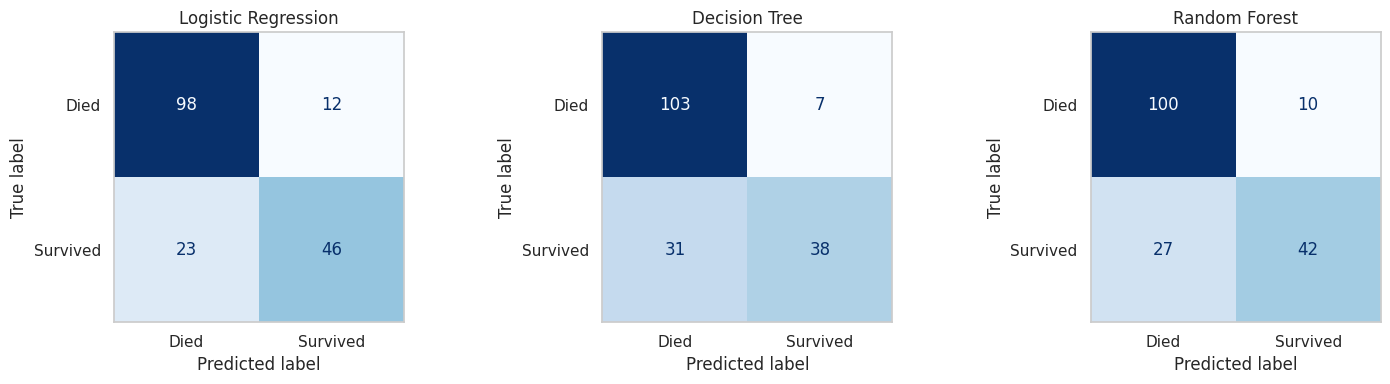

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, cm) in zip(axes, conf_matrices.items()):
    ConfusionMatrixDisplay(cm, display_labels=["Died", "Survived"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

### 6.2 ROC Curves (all models on one chart)
The ROC curve plots the true positive rate (recall) against the false positive rate at every decision threshold. The closer a curve is to the top-left corner, the better the model. The dashed diagonal is a random guess (AUC = 0.5).

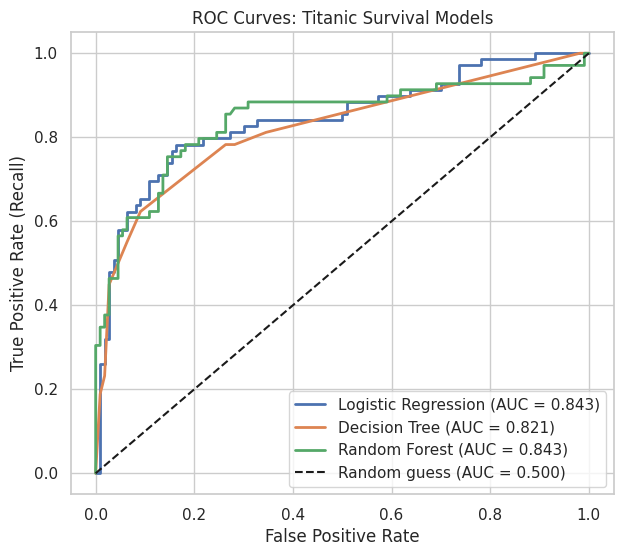

In [9]:
plt.figure(figsize=(7, 6))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves: Titanic Survival Models")
plt.legend(loc="lower right")
plt.show()

## 7. Robustness Check: 5-Fold Cross-Validation
The test set has only 179 passengers, so a single split can be slightly lucky or unlucky. Cross-validation trains and tests each model 5 times on different splits. If the ranking of the models stays the same, the comparison can be trusted more.

In [10]:
cv_rows = []
for name, pipe in models.items():
    scores = cross_val_score(pipe, X, y, cv=5, scoring="roc_auc")
    cv_rows.append({"Model": name,
                    "CV ROC-AUC (mean)": scores.mean(),
                    "CV ROC-AUC (std)": scores.std()})

cv_df = pd.DataFrame(cv_rows).set_index("Model").round(3)
cv_df

,CV ROC-AUC (mean),CV ROC-AUC (std)
Model,,
Logistic Regression,0.848,0.015
Decision Tree,0.842,0.037
Random Forest,0.868,0.032


### 7.1 Which Features Matter? (Random Forest)

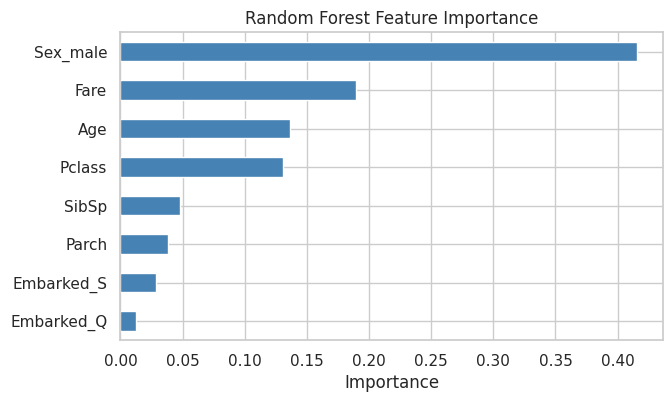

In [11]:
rf = models["Random Forest"].named_steps["model"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(7, 4))
importances.plot(kind="barh", color="steelblue")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

## 8. Conclusion

### Results on the test set (179 passengers)

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC | CV ROC-AUC (5-fold) |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.804 | 0.793 | 0.667 | 0.724 | 0.843 | 0.848 |
| Decision Tree | 0.788 | 0.844 | 0.551 | 0.667 | 0.821 | 0.842 |
| Random Forest | 0.793 | 0.808 | 0.609 | 0.694 | 0.843 | 0.868 |

### What the results show
- All three models are close: accuracy lies between 0.79 and 0.80 and ROC-AUC between 0.82 and 0.84, so none is clearly better on the single test split.
- Logistic Regression has the best accuracy, recall and F1-score on the test split and ties with Random Forest on ROC-AUC.
- Decision Tree has the highest precision (0.844) but the lowest recall (0.551): when it predicts "survived" it is usually right, but it misses many survivors.
- Random Forest has the highest cross-validated ROC-AUC (0.868), which is a more reliable measure than a single 179-row split.
- The most important features are `Sex`, `Fare`, `Age` and `Pclass`, which agrees with the Week 1 EDA.

### Recommendation: deploy the Random Forest
1. It has the highest ROC-AUC in 5-fold cross-validation (0.868), so its advantage is not just luck from one split.
2. On the test split it ties for the best ROC-AUC (0.843) with a good balance of precision and recall.
3. Combining many trees makes it more stable than a single Decision Tree.

### Trade-offs
- Logistic Regression is a very strong alternative: almost as good, simpler, faster and easier to explain. If interpretability matters more, choose it.
- Random Forest is harder to explain, although the feature importance chart helps.
- All models miss a fair share of survivors. If missing a survivor is costly, the decision threshold can be lowered to raise recall at the cost of precision.

### Limitations
- Only 891 passengers and a single 80/20 split, so small differences between models are not statistically meaningful.
- Models were not tuned beyond a basic `max_depth`.